# Ejercicio 7. Separar los cinco grupos

Primero corro el ejemplo de clase tal como está. Después muevo los cinco centros
para que los grupos se vean separados. Dejo los 2000 puntos, random_state=7 y los
mismos ajustes de KMeans para comparar las dos pruebas.


In [1]:
import sys, platform
from pathlib import Path
import json
print('Python:', sys.version.split()[0])
print('Sistema:', platform.system(), platform.machine())
print('Entorno:', 'Google Colab' if 'google.colab' in sys.modules else 'Jupyter local')
Path('resultados').mkdir(exist_ok=True)


Python: 3.11.18
Sistema: Darwin arm64
Entorno: Jupyter local


## Primero, el ejemplo de clase

In [2]:
# Uso Python 3.5 en adelante.
import sys
assert sys.version_info >= (3, 5)

# Uso Scikit-Learn 0.20 en adelante.
import sklearn
assert sklearn.__version__ >= "0.20"

# Aquí cargo lo que voy a usar.
import numpy as np
import os

# Dejo la misma semilla para poder repetir la prueba.
np.random.seed(42)

# Ajusto el tamaño del texto de las gráficas.
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc('axes', labelsize=14)
mpl.rc('xtick', labelsize=12)
mpl.rc('ytick', labelsize=12)

# Aquí se van a guardar las gráficas.
PROJECT_ROOT_DIR = "."
CHAPTER_ID = "unsupervised_learning"
IMAGES_PATH = os.path.join(PROJECT_ROOT_DIR, "images", CHAPTER_ID)
os.makedirs(IMAGES_PATH, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = os.path.join(IMAGES_PATH, fig_id + "." + fig_extension)
    print("Saving figure", fig_id)
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

# Agrupar datos

**Clasificar y agrupar: ¿qué cambia?**

In [3]:
from sklearn.datasets import load_iris

In [4]:
data = load_iris()
X = data.data
y = data.target
data.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

Saving figure classification_vs_clustering_plot


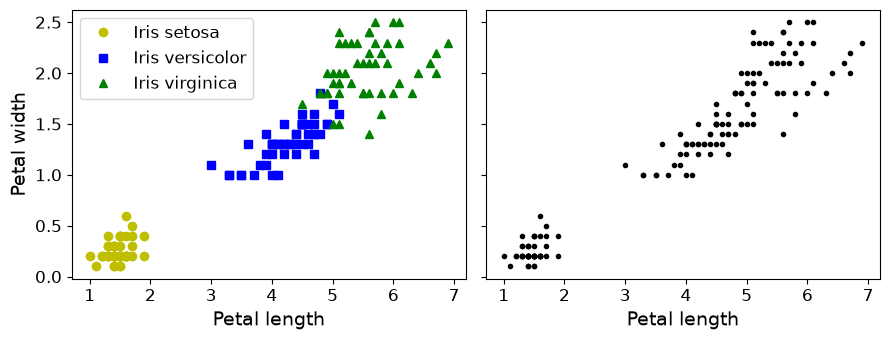

In [5]:
plt.figure(figsize=(9, 3.5))

plt.subplot(121)
plt.plot(X[y==0, 2], X[y==0, 3], "yo", label="Iris setosa")
plt.plot(X[y==1, 2], X[y==1, 3], "bs", label="Iris versicolor")
plt.plot(X[y==2, 2], X[y==2, 3], "g^", label="Iris virginica")
plt.xlabel("Petal length", fontsize=14)
plt.ylabel("Petal width", fontsize=14)
plt.legend(fontsize=12)

plt.subplot(122)
plt.scatter(X[:, 2], X[:, 3], c="k", marker=".")
plt.xlabel("Petal length", fontsize=14)
plt.tick_params(labelleft=False)

save_fig("classification_vs_clustering_plot")
plt.show()

### K-medias

Primero voy a crear las nubes de puntos.

In [6]:
from sklearn.datasets import make_blobs

In [7]:
blob_centers = np.array(
    [[ 0.2,  2.3],
     [-1.5 ,  2.3],
     [-2.8,  1.8],
     [-2.8,  2.8],
     [-2.8,  1.3]])
blob_std = np.array([0.4, 0.3, 0.1, 0.1, 0.1])

In [8]:
X, y = make_blobs(n_samples=2000, centers=blob_centers,
                  cluster_std=blob_std, random_state=7)

Aquí se ve cómo quedaron los puntos.

In [9]:
def plot_clusters(X, y=None):
    plt.scatter(X[:, 0], X[:, 1], c=y, s=1)
    plt.xlabel("$x_1$", fontsize=14)
    plt.ylabel("$x_2$", fontsize=14, rotation=0)

Saving figure blobs_plot


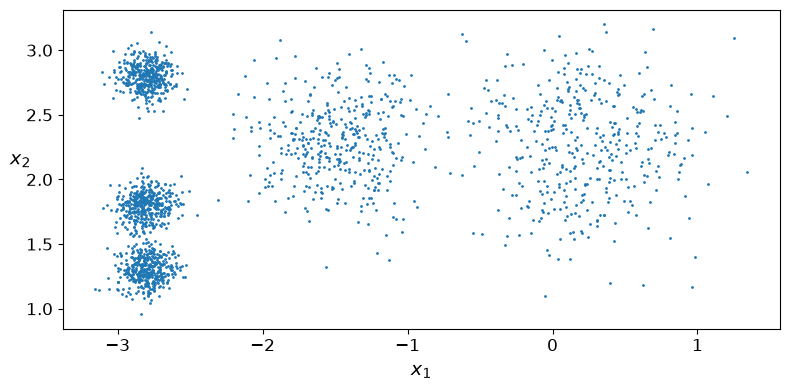

In [10]:
plt.figure(figsize=(8, 4))
plot_clusters(X)
save_fig("blobs_plot")
plt.show()

**Entrenar y asignar los grupos**

Ahora uso KMeans. Busca los centros y pone cada punto en el grupo del centro que tenga más cerca.

In [11]:
from sklearn.cluster import KMeans

In [12]:
k = 5
kmeans = KMeans(n_clusters=k, random_state=42, init='k-means++', n_init='auto')
# También se puede probar un inicio al azar con init="random".
y_pred = kmeans.fit_predict(X)

Cada punto quedó en uno de los cinco grupos. Estos números indican cuál le tocó.

In [13]:
y_pred

array([2, 2, 4, ..., 1, 4, 2], shape=(2000,), dtype=int32)

In [14]:
print(y_pred[:10])

[2 2 4 2 2 2 2 2 3 2]


In [15]:
y_pred is kmeans.labels_

True

Estos son los cinco centros que encontró el algoritmo.

In [16]:
kmeans.cluster_centers_

array([[-0.066884  ,  2.10378803],
       [-2.79290307,  2.79641063],
       [-2.80214068,  1.55162671],
       [-1.47468607,  2.28399066],
       [ 0.47042841,  2.41380533]])

KMeans guarda el grupo de cada punto en `labels_`. Aquí esas etiquetas son números de grupo, no nombres de especies ni clases que yo le haya dado.

In [17]:
kmeans.labels_

array([2, 2, 4, ..., 1, 4, 2], shape=(2000,), dtype=int32)

También puedo darle puntos nuevos para ver en qué grupo los pondría.

In [18]:
X_new = np.array([[0, 2], [3, 2], [-3, 3], [-3, 2.5]])
kmeans.predict(X_new)

array([0, 4, 1, 1], dtype=int32)

In [19]:
def plot_data(X):
    plt.plot(X[:, 0], X[:, 1], 'k.', markersize=2)

def plot_centroids(centroids, weights=None, circle_color='w', cross_color='k'):
    if weights is not None:
        centroids = centroids[weights > weights.max() / 10]
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='o', s=35, linewidths=8,
                color=circle_color, zorder=10, alpha=0.9)
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='x', s=2, linewidths=12,
                color=cross_color, zorder=11, alpha=1)

def plot_decision_boundaries(clusterer, X, resolution=1000, show_centroids=True,
                             show_xlabels=True, show_ylabels=True):
    mins = X.min(axis=0) - 0.1
    maxs = X.max(axis=0) + 0.1
    xx, yy = np.meshgrid(np.linspace(mins[0], maxs[0], resolution),
                         np.linspace(mins[1], maxs[1], resolution))
    Z = clusterer.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                cmap="Pastel2")
    plt.contour(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                linewidths=1, colors='k')
    plot_data(X)
    if show_centroids:
        plot_centroids(clusterer.cluster_centers_)

    if show_xlabels:
        plt.xlabel("$x_1$", fontsize=14)
    else:
        plt.tick_params(labelbottom=False)
    if show_ylabels:
        plt.ylabel("$x_2$", fontsize=14, rotation=0)
    else:
        plt.tick_params(labelleft=False)

Saving figure voronoi_plot


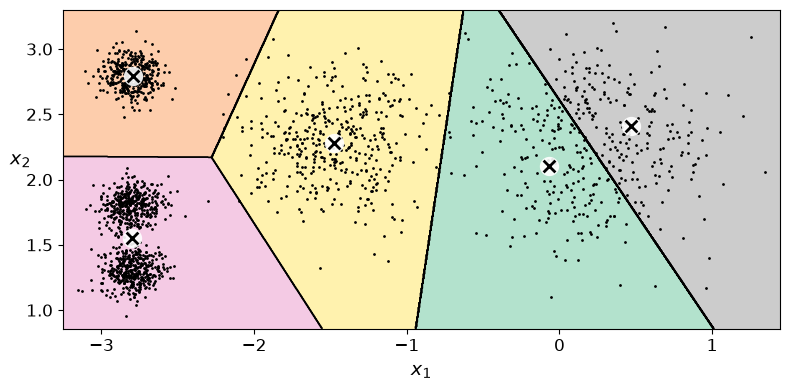

In [20]:
plt.figure(figsize=(8, 4))
plot_decision_boundaries(kmeans, X)
save_fig("voronoi_plot")
plt.show()

### Cómo trabaja K-medias

La idea es sencilla:

- Elegir k puntos como centros iniciales.
- Poner cada punto con el centro más cercano.
- Mover cada centro al promedio de los puntos de su grupo.
- Repetir hasta que los centros dejen de moverse.

Para ver los pasos con más calma, uso `init="random"`, `n_init=1` y `algorithm="lloyd"`. Así arranca con centros al azar y hace un solo intento.

In [ ]:
kmeans_iter1 = KMeans(n_clusters=5, init="random", n_init=1,
                     algorithm="lloyd", max_iter=1, random_state=0)
kmeans_iter2 = KMeans(n_clusters=5, init="random", n_init=1,
                     algorithm="lloyd", max_iter=2, random_state=0)
kmeans_iter3 = KMeans(n_clusters=5, init="random", n_init=1,
                     algorithm="lloyd", max_iter=3, random_state=0)
kmeans_iter1.fit(X)
kmeans_iter2.fit(X)
kmeans_iter3.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",5
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'random'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",1
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",3
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",0
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](5, 2)","[[-1.47, 2.2

Aquí comparo esas tres vueltas.

Saving figure kmeans_algorithm_plot


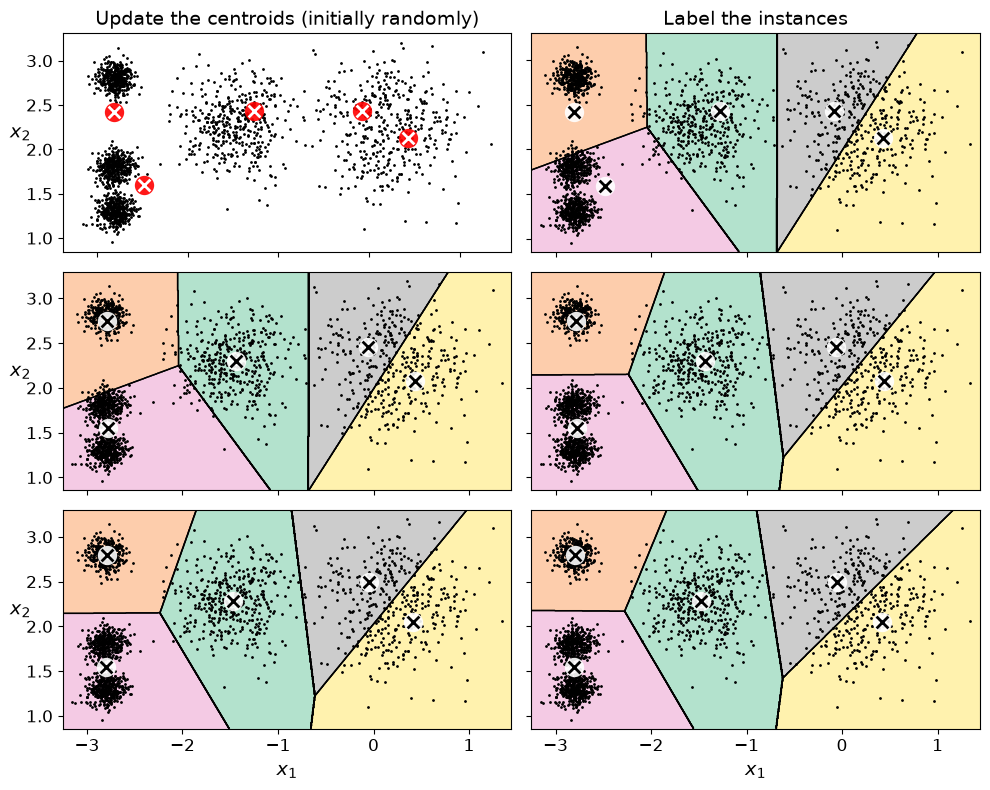

In [ ]:
plt.figure(figsize=(10, 8))

plt.subplot(321)
plot_data(X)
plot_centroids(kmeans_iter1.cluster_centers_, circle_color='r', cross_color='w')
plt.ylabel("$x_2$", fontsize=14, rotation=0)
plt.tick_params(labelbottom=False)
plt.title("Update the centroids (initially randomly)", fontsize=14)

plt.subplot(322)
plot_decision_boundaries(kmeans_iter1, X, show_xlabels=False, show_ylabels=False)
plt.title("Label the instances", fontsize=14)

plt.subplot(323)
plot_decision_boundaries(kmeans_iter1, X, show_centroids=False, show_xlabels=False)
plot_centroids(kmeans_iter2.cluster_centers_)

plt.subplot(324)
plot_decision_boundaries(kmeans_iter2, X, show_xlabels=False, show_ylabels=False)

plt.subplot(325)
plot_decision_boundaries(kmeans_iter2, X, show_centroids=False)
plot_centroids(kmeans_iter3.cluster_centers_)

plt.subplot(326)
plot_decision_boundaries(kmeans_iter3, X, show_ylabels=False)

save_fig("kmeans_algorithm_plot")
plt.show()

**Qué pasa si cambian los centros del inicio**

Arrancar al azar puede dar resultados distintos. Aquí cambio la semilla para ver dos formas de agrupar los mismos puntos.

In [ ]:
def plot_clusterer_comparison(clusterer1, clusterer2, X, title1=None, title2=None):
    clusterer1.fit(X)
    clusterer2.fit(X)

    plt.figure(figsize=(10, 3.2))

    plt.subplot(121)
    plot_decision_boundaries(clusterer1, X)
    if title1:
        plt.title(title1, fontsize=14)

    plt.subplot(122)
    plot_decision_boundaries(clusterer2, X, show_ylabels=False)
    if title2:
        plt.title(title2, fontsize=14)

Saving figure kmeans_variability_plot


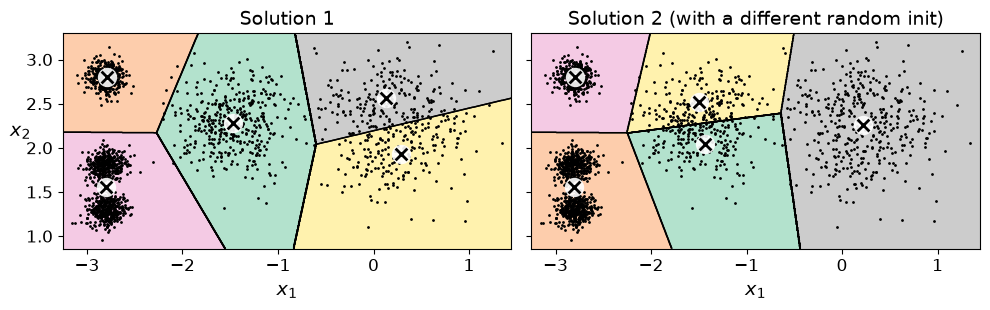

In [ ]:
kmeans_rnd_init1 = KMeans(n_clusters=5, init="random", n_init=1,
                         algorithm="lloyd", random_state=2)
kmeans_rnd_init2 = KMeans(n_clusters=5, init="random", n_init=1,
                         algorithm="lloyd", random_state=5)

plot_clusterer_comparison(kmeans_rnd_init1, kmeans_rnd_init2, X,
                          "Solution 1", "Solution 2 (with a different random init)")

save_fig("kmeans_variability_plot")
plt.show()

### Inercia

Como aquí no le doy las respuestas al algoritmo, necesito otra forma de comparar. La inercia mide qué tan lejos quedaron los puntos de sus centros: mientras más baja sea, más juntos quedaron dentro de cada grupo.

In [25]:
kmeans.inertia_

224.07433122515727

Para calcularla, sumo las distancias al cuadrado de cada punto a su centro más cercano.

In [26]:
X_dist = kmeans.transform(X)
np.sum(X_dist[np.arange(len(X_dist)), kmeans.labels_]**2)

np.float64(224.07433122515744)

`score()` devuelve la inercia con signo negativo. Así, un score más alto corresponde a una inercia más baja.

In [27]:
kmeans.score(X)

-224.07433122515727

### Probar varios arranques

In [28]:
kmeans_rnd_init1.inertia_

219.58201503602288

In [29]:
kmeans_rnd_init2.inertia_

239.19226403410454

Estas dos pruebas tienen más inercia que la primera. Sus grupos quedaron menos juntos alrededor de sus centros.

Con `n_init=10`, KMeans prueba diez arranques y se queda con el que tenga menos inercia.

In [30]:
kmeans_rnd_10_inits = KMeans(n_clusters=5, init="random", n_init=10,
                              algorithm="lloyd", random_state=2)
kmeans_rnd_10_inits.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",5
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'random'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",2
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](5, 2)","[[-1.47, 

Al probar varios arranques, vuelvo a obtener una solución parecida a la primera, con poca inercia para k=5.

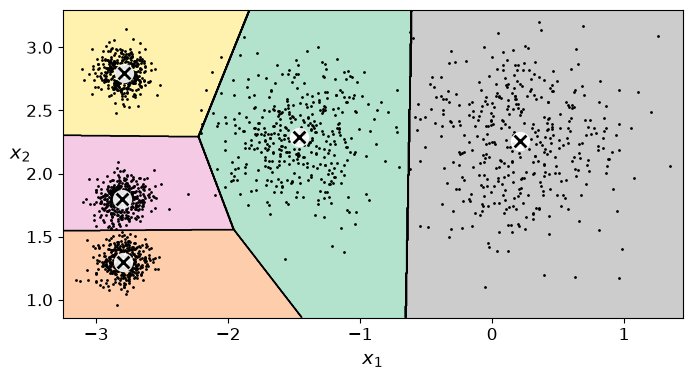

In [31]:
plt.figure(figsize=(8, 4))
plot_decision_boundaries(kmeans_rnd_10_inits, X)
plt.show()

### Elegir los centros del inicio

También se puede  usar k-means++

- El primer centro se elige al azar.
- Para elegir los siguientes, tienen más oportunidad los puntos que están lejos de los centros que ya hay.
- La probabilidad usa la distancia al cuadrado: $D(x_i)^2 / \sum_{j=1}^{m} D(x_j)^2$.
- Repito hasta tener los k centros.

Después de elegir esos centros, sigue el KMeans de siempre. Empezar con centros más separados suele evitar algunos malos arranques y puede necesitar menos intentos.

In [32]:
KMeans()

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",8
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",None
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'


In [33]:
good_init = np.array([[-3, 3], [-3, 2], [-3, 1], [-1, 2], [0, 2]])
kmeans = KMeans(n_clusters=5, init=good_init, n_init=1, random_state=42)
kmeans.fit(X)
kmeans.inertia_

211.5985372581684

Aquí pruebo `algorithm="elkan"` y lo comparo con `algorithm="lloyd"`, la versión normal.

In [34]:
%timeit -n 50 KMeans(algorithm="elkan", random_state=42).fit(X)

2.76 ms ± 326 μs per loop (mean ± std. dev. of 7 runs, 50 loops each)


In [35]:
%timeit -n 50 KMeans(algorithm="lloyd", random_state=42).fit(X)

2.05 ms ± 183 μs per loop (mean ± std. dev. of 7 runs, 50 loops each)


### ¿Cuántos grupos conviene usar?

Voy a ver qué pasa si uso menos o más de cinco grupos.

Saving figure bad_n_clusters_plot


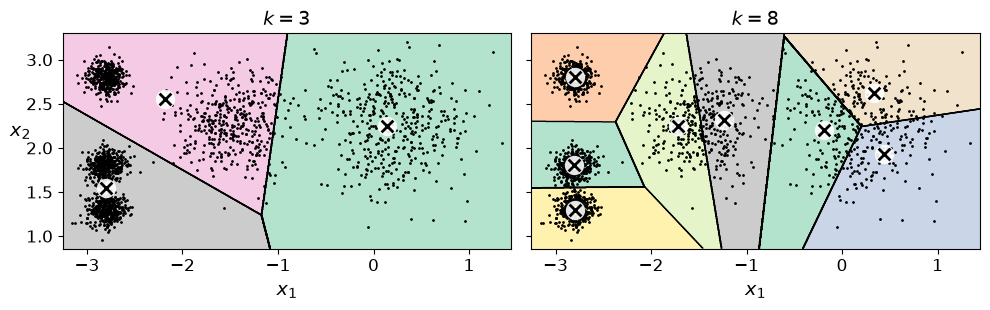

In [36]:
kmeans_k3 = KMeans(n_clusters=3, random_state=42)
kmeans_k8 = KMeans(n_clusters=8, random_state=42)

plot_clusterer_comparison(kmeans_k3, kmeans_k8, X, "$k=3$", "$k=8$")
save_fig("bad_n_clusters_plot")
plt.show()

Estas dos formas de separar los puntos no se ven tan bien. Ahora reviso sus inercias.

In [37]:
kmeans_k3.inertia_

653.2167190021553

In [38]:
kmeans_k8.inertia_

127.13141880461836

No sirve elegir el k que dé la menor inercia, porque casi siempre baja al agregar más grupos. Mejor dibujo la curva y busco dónde deja de bajar tan rápido: ese cambio es el codo.

In [39]:
kmeans_per_k = [KMeans(n_clusters=k, random_state=42).fit(X)
                for k in range(1, 10)]
inertias = [model.inertia_ for model in kmeans_per_k]

Saving figure inertia_vs_k_plot


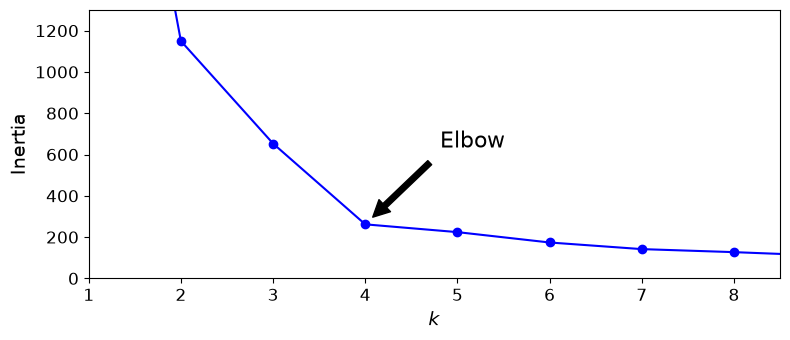

In [40]:
plt.figure(figsize=(8, 3.5))
plt.plot(range(1, 10), inertias, "bo-")
plt.xlabel("$k$", fontsize=14)
plt.ylabel("Inertia", fontsize=14)
plt.annotate('Elbow',
             xy=(4, inertias[3]),
             xytext=(0.55, 0.55),
             textcoords='figure fraction',
             fontsize=16,
             arrowprops=dict(facecolor='black', shrink=0.1)
            )
plt.axis([1, 8.5, 0, 1300])
save_fig("inertia_vs_k_plot")
plt.show()

Aquí el codo se ve cerca de k=4. Con menos grupos se juntan demasiados puntos y con más ya se empiezan a partir algunas nubes. Aunque creé cinco centros, dos grupos de abajo a la izquierda están tan cerca que KMeans puede juntarlos.

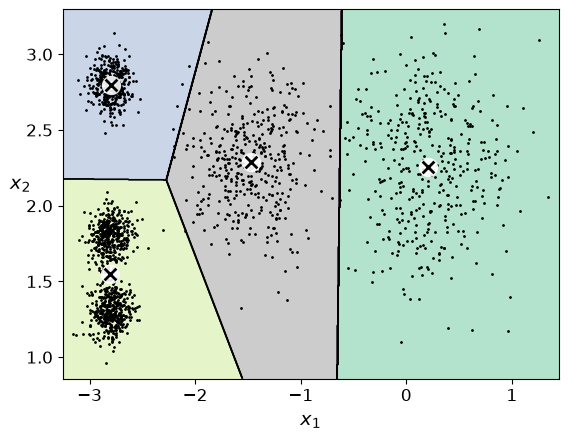

In [41]:
plot_decision_boundaries(kmeans_per_k[4-1], X)
plt.show()

La silueta también ayuda a elegir k. Compara qué tan cerca está cada punto de su propio grupo y de los demás.

Se calcula como $(b-a)/\max(a,b)$: a es la distancia media a los puntos de su grupo y b es la distancia media al otro grupo más cercano. Cerca de +1 está bien separado; cerca de 0 está entre grupos; si sale negativa, puede estar en el grupo equivocado.

Aquí dibujo la silueta promedio para cada k.

In [42]:
from sklearn.metrics import silhouette_score

In [43]:
silhouette_score(X, kmeans.labels_)

0.6555176425728279

In [44]:
silhouette_scores = [silhouette_score(X, model.labels_)
                     for model in kmeans_per_k[1:]]

Saving figure silhouette_score_vs_k_plot


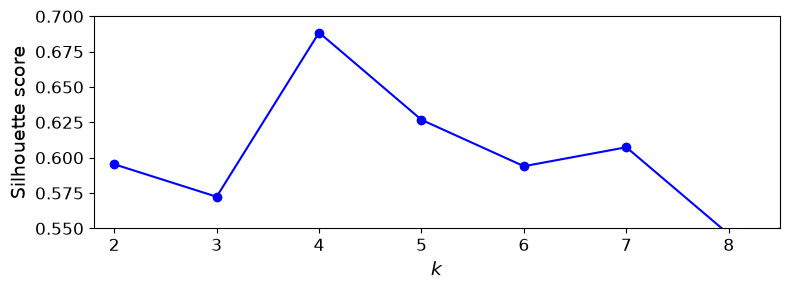

In [45]:
plt.figure(figsize=(8, 3))
plt.plot(range(2, 10), silhouette_scores, "bo-")
plt.xlabel("$k$", fontsize=14)
plt.ylabel("Silhouette score", fontsize=14)
plt.axis([1.8, 8.5, 0.55, 0.7])
save_fig("silhouette_score_vs_k_plot")
plt.show()

La silueta también deja bien parado a k=4. Con k=5 todavía sale una separación bastante buena.

Ahora veo la silueta de cada punto, separada por grupo. Esto ayuda a ver si un buen promedio esconde algún grupo que quedó mal.

Saving figure silhouette_analysis_plot


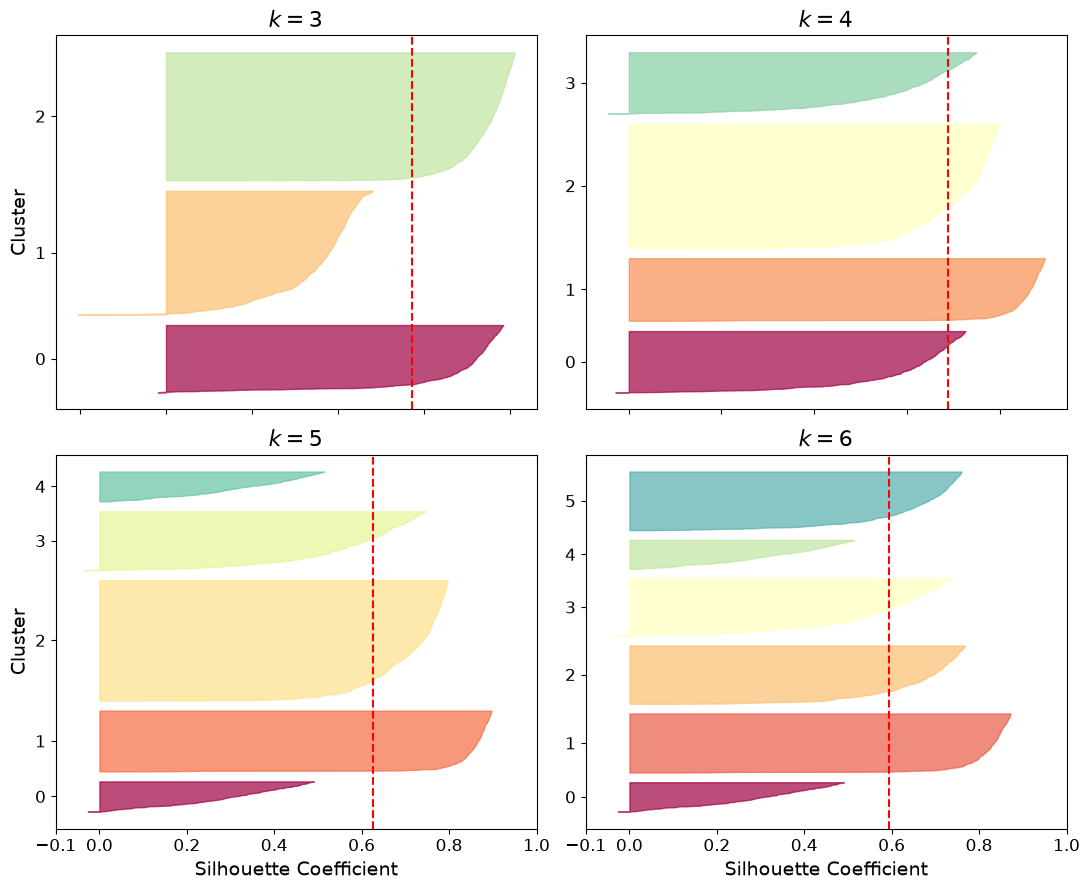

In [46]:
from sklearn.metrics import silhouette_samples
from matplotlib.ticker import FixedLocator, FixedFormatter

plt.figure(figsize=(11, 9))

for k in (3, 4, 5, 6):
    plt.subplot(2, 2, k - 2)

    y_pred = kmeans_per_k[k - 1].labels_
    silhouette_coefficients = silhouette_samples(X, y_pred)

    padding = len(X) // 30
    pos = padding
    ticks = []
    for i in range(k):
        coeffs = silhouette_coefficients[y_pred == i]
        coeffs.sort()

        color = mpl.cm.Spectral(i / k)
        plt.fill_betweenx(np.arange(pos, pos + len(coeffs)), 0, coeffs,
                          facecolor=color, edgecolor=color, alpha=0.7)
        ticks.append(pos + len(coeffs) // 2)
        pos += len(coeffs) + padding

    plt.gca().yaxis.set_major_locator(FixedLocator(ticks))
    plt.gca().yaxis.set_major_formatter(FixedFormatter(range(k)))
    if k in (3, 5):
        plt.ylabel("Cluster")

    if k in (5, 6):
        plt.gca().set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])
        plt.xlabel("Silhouette Coefficient")
    else:
        plt.tick_params(labelbottom=False)

    plt.axvline(x=silhouette_scores[k - 2], color="red", linestyle="--")
    plt.title("$k={}$".format(k), fontsize=16)

save_fig("silhouette_analysis_plot")
plt.show()

In [47]:
# Guardo esta primera prueba antes de usar la imagen de la catarina.
import shutil
centros_originales = blob_centers.copy()
std_originales = blob_std.copy()
X_original = X.copy()
resultado_original = {
    'centros': centros_originales.tolist(), 'std': std_originales.tolist(),
    'inertias': [float(v) for v in inertias],
    'siluetas': [float(v) for v in silhouette_scores],
    'mejor_k_silueta': int(np.argmax(silhouette_scores) + 2),
    'codo_visual': 4,
}
for src, dest in [('blobs_plot', 'original_scatter'), ('voronoi_plot', 'original_voronoi'),
                  ('inertia_vs_k_plot', 'original_codo'), ('silhouette_score_vs_k_plot', 'original_silueta')]:
    shutil.copyfile(Path(IMAGES_PATH) / (src + '.png'), Path('resultados') / (dest + '.png'))
print('Original:')
print('Inercia k=3:', inertias[2], 'k=5:', inertias[4], 'k=8:', inertias[7])
print('Silueta máxima en k=', resultado_original['mejor_k_silueta'])


Original:
Inercia k=3: 653.2167190021553 k=5: 224.07433122515727 k=8: 127.13141880461836
Silueta máxima en k= 4


En estas gráficas, k=4 y k=5 se ven como buenas opciones. Los grupos tienen tamaños parecidos y alcanzan valores por arriba de la línea del promedio.

## Usar KMeans para reducir los colores de una imagen

In [48]:
import urllib
# Bajo la imagen de la catarina.
images_path = os.path.join(PROJECT_ROOT_DIR, "images", "unsupervised_learning")
os.makedirs(images_path, exist_ok=True)
DOWNLOAD_ROOT = "https://raw.githubusercontent.com/ageron/handson-ml2/master/"
filename = "ladybug.png"
print("Downloading", filename)
url = DOWNLOAD_ROOT + "images/unsupervised_learning/" + filename
urllib.request.urlretrieve(url, os.path.join(images_path, filename))

('./images/unsupervised_learning/ladybug.png',
 <http.client.HTTPMessage at 0x112d47190>)

In [49]:
from matplotlib.image import imread
image = imread(os.path.join(images_path, filename))
image.shape

(533, 800, 3)

In [50]:
X = image.reshape(-1, 3)
kmeans = KMeans(n_clusters=8, random_state=42).fit(X)
segmented_img = kmeans.cluster_centers_[kmeans.labels_]
segmented_img = segmented_img.reshape(image.shape)

In [51]:
segmented_imgs = []
n_colors = (10, 8, 6, 4, 2)
for n_clusters in n_colors:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42).fit(X)
    segmented_img = kmeans.cluster_centers_[kmeans.labels_]
    segmented_imgs.append(segmented_img.reshape(image.shape))

Saving figure image_segmentation_diagram


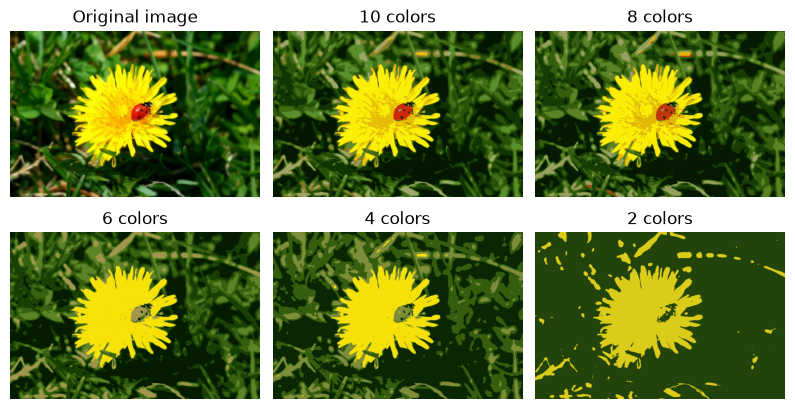

In [52]:
plt.figure(figsize=(10,5))
plt.subplots_adjust(wspace=0.05, hspace=0.1)

plt.subplot(231)
plt.imshow(image)
plt.title("Original image")
plt.axis('off')

for idx, n_clusters in enumerate(n_colors):
    plt.subplot(232 + idx)
    plt.imshow(segmented_imgs[idx])
    plt.title("{} colors".format(n_clusters))
    plt.axis('off')

save_fig('image_segmentation_diagram', tight_layout=False)
plt.show()

## Ahora separo más los cinco centros

Solo muevo los centros a (-4, -2), (0, -2), (4, -2), (-2, 2) y (2, 2).
Dejo las mismas cinco desviaciones. En el dibujo marco los centros y unos círculos
de radio 2 × std para dar una idea del tamaño de cada nube.

Vuelvo a crear los 2000 puntos con make_blobs, porque en la parte de la catarina
la variable X quedó con los píxeles de la imagen.

In [53]:
blob_centers = np.array([[-4., -2.], [0., -2.], [4., -2.], [-2., 2.], [2., 2.]])
blob_std = std_originales.copy()
X, y = make_blobs(n_samples=2000, centers=blob_centers,
                  cluster_std=blob_std, random_state=7)
X_blobs = X.copy()
assert X.shape == (2000, 2) and len(blob_centers) == 5
print('Centros y desviaciones:')
for c, s in zip(blob_centers, blob_std):
    print(c, 'std =', s)
k = 5
kmeans = KMeans(n_clusters=k, random_state=42, init='k-means++', n_init='auto')
y_pred = kmeans.fit_predict(X)
kmeans_per_k = [KMeans(n_clusters=k, random_state=42).fit(X)
                for k in range(1, 10)]
inertias = [model.inertia_ for model in kmeans_per_k]
silhouette_scores = [silhouette_score(X, model.labels_) for model in kmeans_per_k[1:]]
resultado_modificado = {
    'centros': blob_centers.tolist(), 'std': blob_std.tolist(),
    'inertias': [float(v) for v in inertias],
    'siluetas': [float(v) for v in silhouette_scores],
    'mejor_k_silueta': int(np.argmax(silhouette_scores) + 2),
    'codo_visual': 5,
}
print('Inercia k=3:', inertias[2], 'k=5:', inertias[4], 'k=8:', inertias[7])
print('Silueta máxima en k=', resultado_modificado['mejor_k_silueta'])


Centros y desviaciones:
[-4. -2.] std = 0.4
[ 0. -2.] std = 0.3
[ 4. -2.] std = 0.1
[-2.  2.] std = 0.1
[2. 2.] std = 0.1
Inercia k=3: 6579.095962141831 k=5: 216.38893260079527 k=8: 122.8668261751618
Silueta máxima en k= 5


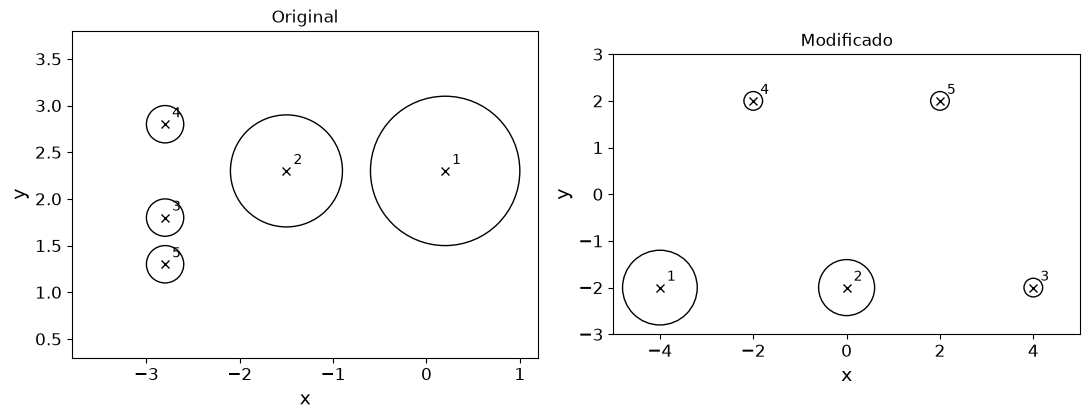

In [54]:
# Comparo los centros de antes y después con círculos de radio 2*std.
from matplotlib.patches import Circle
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, centers, deviations, title in zip(
        axes, [centros_originales, blob_centers], [std_originales, blob_std], ['Original', 'Modificado']):
    for i, (center, std) in enumerate(zip(centers, deviations)):
        ax.plot(*center, 'kx')
        ax.add_patch(Circle(center, 2*std, fill=False, edgecolor='black'))
        ax.annotate(str(i+1), center, xytext=(5, 5), textcoords='offset points')
    ax.set_xlim(centers[:, 0].min()-1, centers[:, 0].max()+1)
    ax.set_ylim(centers[:, 1].min()-1, centers[:, 1].max()+1)
    ax.set_aspect('equal'); ax.set_title(title); ax.set_xlabel('x'); ax.set_ylabel('y')
fig.tight_layout(); fig.savefig('resultados/centros.png', dpi=160); plt.show()


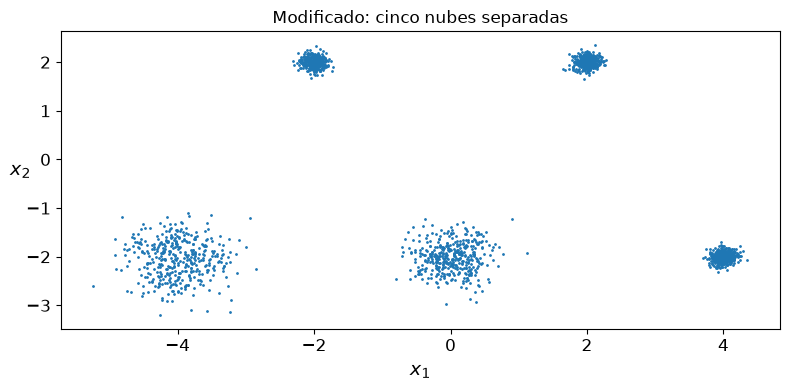

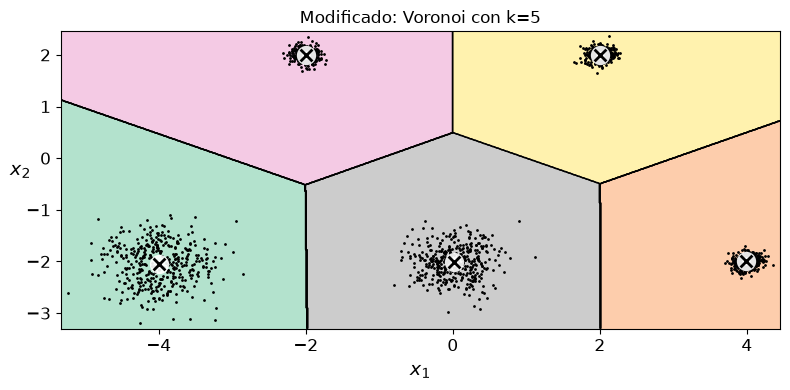

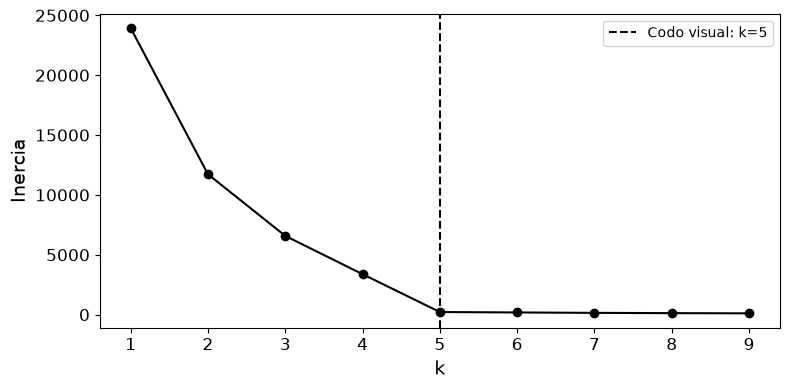

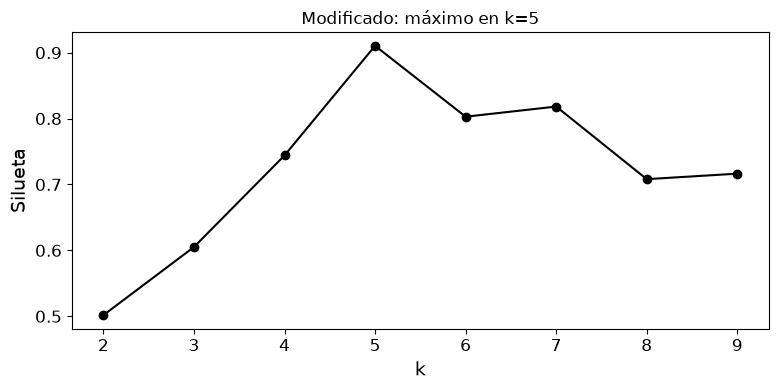

In [55]:
# Aquí van las cuatro gráficas con los centros nuevos.
plt.figure(figsize=(8, 4)); plot_clusters(X)
plt.title('Modificado: cinco nubes separadas')
plt.tight_layout(); plt.savefig('resultados/modificado_scatter.png', dpi=160); plt.show()

plt.figure(figsize=(8, 4)); plot_decision_boundaries(kmeans, X)
plt.title('Modificado: Voronoi con k=5')
plt.tight_layout(); plt.savefig('resultados/modificado_voronoi.png', dpi=160); plt.show()

plt.figure(figsize=(8, 4)); plt.plot(range(1, 10), inertias, 'ko-')
plt.axvline(5, color='black', linestyle='--', label='Codo visual: k=5')
plt.xticks(range(1, 10)); plt.xlabel('k'); plt.ylabel('Inercia'); plt.legend()
plt.tight_layout(); plt.savefig('resultados/modificado_codo.png', dpi=160); plt.show()

plt.figure(figsize=(8, 4)); plt.plot(range(2, 10), silhouette_scores, 'ko-')
plt.xticks(range(2, 10)); plt.xlabel('k'); plt.ylabel('Silueta')
plt.title('Modificado: máximo en k=' + str(resultado_modificado['mejor_k_silueta']))
plt.tight_layout(); plt.savefig('resultados/modificado_silueta.png', dpi=160); plt.show()


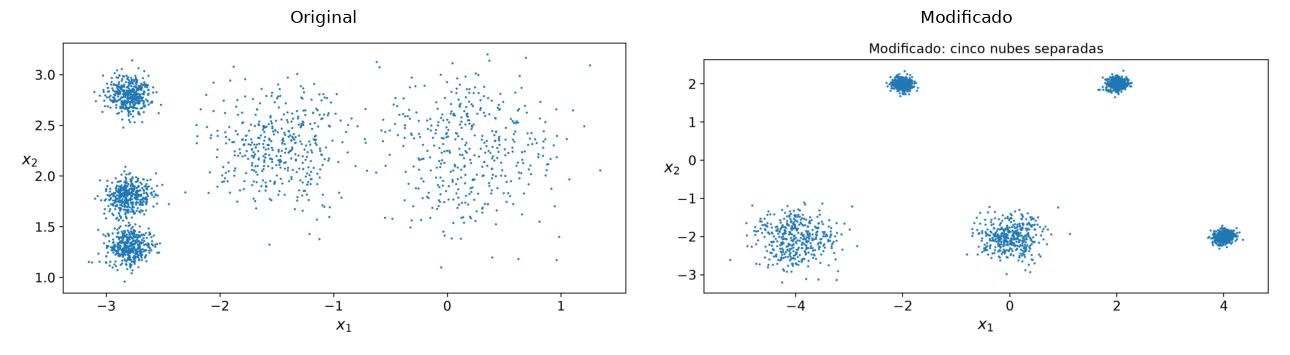

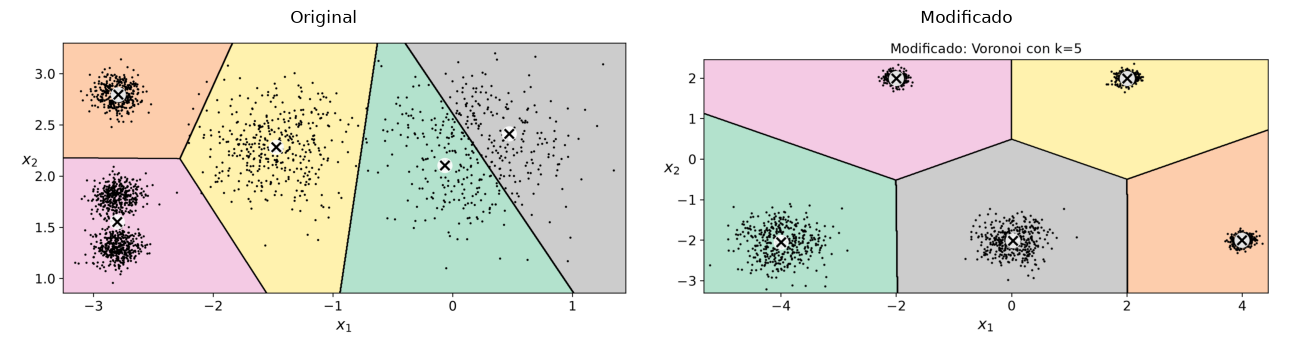

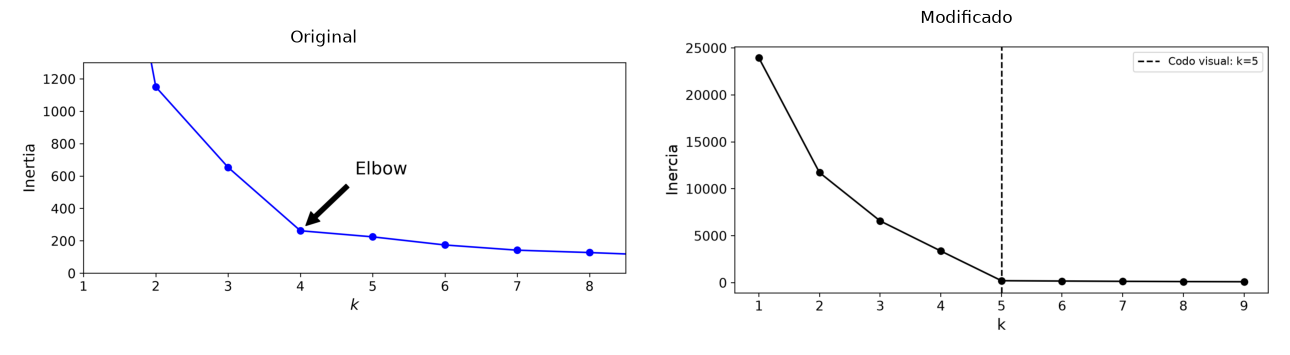

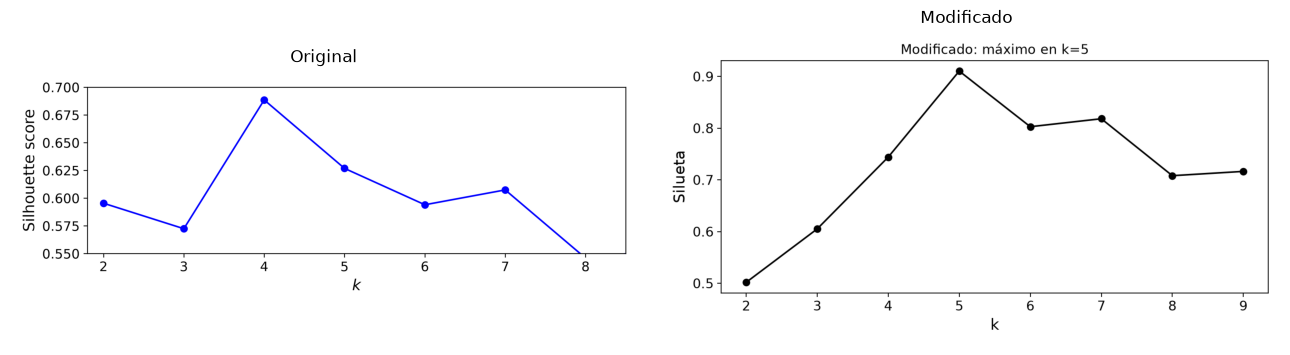

Versión      k       Inercia       Silueta
Original     1   3534.836087            -
Original     2   1149.891350     0.595363
Original     3    653.216719     0.572390
Original     4    261.796778     0.688532
Original     5    224.074331     0.626789
Original     6    173.876091     0.593983
Original     7    141.797238     0.607376
Original     8    127.131419     0.545857
Original     9    109.891757     0.553633
Modificado   1  23945.495608            -
Modificado   2  11726.616193     0.501749
Modificado   3   6579.095962     0.605102
Modificado   4   3377.953565     0.744057
Modificado   5    216.388933     0.910366
Modificado   6    179.479715     0.802792
Modificado   7    145.936539     0.818203
Modificado   8    122.866826     0.708064
Modificado   9    105.792544     0.716373


1867

In [56]:
# Pongo cada gráfica junto a la de antes para compararlas.
from matplotlib.image import imread
for kind in ['scatter', 'voronoi', 'codo', 'silueta']:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, name in zip(axes, ['original', 'modificado']):
        ax.imshow(imread('resultados/' + name + '_' + kind + '.png'))
        ax.axis('off'); ax.set_title(name.capitalize())
    fig.tight_layout()
    fig.savefig('resultados/comparacion_' + kind + '.png', dpi=150)
    plt.show()

print('Versión      k       Inercia       Silueta')
for name, data in [('Original', resultado_original), ('Modificado', resultado_modificado)]:
    for k in range(1, 10):
        sil = '-' if k == 1 else f"{data['siluetas'][k-2]:.6f}"
        print(f"{name:12} {k} {data['inertias'][k-1]:13.6f} {sil:>12}")
resultados = {'original': resultado_original, 'modificado': resultado_modificado,
              'n_samples': 2000, 'semilla_datos': 7, 'semilla_kmeans': 42,
              'python': sys.version.split()[0], 'sklearn': sklearn.__version__,
              'entorno': 'Colab' if 'google.colab' in sys.modules else 'local'}
Path('resultados/metricas.json').write_text(json.dumps(resultados, indent=2), encoding='utf-8')


### Reporte

En la primera prueba puse cinco centros, pero dos grupos de la izquierda quedaron
muy juntos. Por eso el codo se ve cerca de k=4, aunque había cinco centros.
La inercia salió en 653.22 con k=3,
261.80 con k=4, 224.07 con k=5 y
127.13 con k=8. La mejor silueta quedó en
k=4, con 0.6885.

Después solo moví los cinco centros. Dejé las desviaciones,
los 2000 puntos, la semilla y los mismos ajustes. Ahora sí se ven cinco nubes.
Con k=4 la inercia fue 3377.95 y con k=5 bajó a
216.39. Con k=8 quedó en 122.87: baja un poco más,
pero ya está dividiendo nubes que estaban separadas.
El codo ahora se ve cerca de k=5. La mejor silueta quedó en
k=5, con 0.9104.

El codo lo elijo mirando la curva, así que no es un valor exacto. En esta prueba
el codo y la silueta apuntan a cinco grupos. Si todavía salieran cuatro, tendría
que alejar más los centros que están juntos, tomando en cuenta sus desviaciones.
No conviene elegir solo la inercia más baja, porque casi siempre baja al aumentar k.
